In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import pickle
import aux_functions as aux
importlib.reload(aux)

def read_pkl(path):
    with open(path, "rb") as file:
        return pickle.load(file) 

def write_pkl(var, path):
    with open(path, "wb") as file:
        pickle.dump(var, file)

In [6]:
MONKEY = 'M08'
SESSION = 'm08cat135'
STR_DETAILS = f'Session {SESSION}'

In [10]:
dicio_sacc_vectors = read_pkl("pkl_aux_data\\dicio_sacc_vectors.pkl")
df_cell = read_pkl("session_data/all_sessions.pkl")

In [30]:
print(input('v4 nao foveal!'))
df_session = df_cell.query("session == @SESSION and brain_area == 'V4' and RF_type != 'Focal Foveal'")
df_session

,start,search,mapRF,grid_coord,depth,brain_area,sample,array,prefer,SI,RFin,RFout,coreRFin,,RF_type,session,neuron_id
2031,128,m08cat135spk098a,m08det134spk098a,+1-5,610,V4,NaN,0.0,NaN,0.139700,"4,5,6","0,18,19,1,2,3,7,8,9,10,11,12,13,16,17,20",NaN,NaN,Peripheral,m08cat135,spk098a
2032,129,m08cat135spk098b,m08det134spk098b,+1-5,610,V4,NaN,0.0,NaN,-0.019987,"4,5,6,14,15,13","0,18,11,1,2,3,7,8,9,10,12,16,17,19,20",NaN,NaN,Peripheral,m08cat135,spk098b
2033,130,m08cat135spk098c,m08det134spk098c,+1-5,610,V4,NaN,0.0,NaN,0.044452,"5,6,14,15,13,16","0,1,2,3,4,7,8,9,10,11,12,17,18,19,20",NaN,NaN,Peripheral,m08cat135,spk098c
2034,133,m08cat135spk100a,m08det134spk100a,+1-5,630,V4,NaN,0.0,NaN,-0.050348,"4,5,6,13,15,14","0,18,19,1,2,3,7,8,9,10,11,12,16,17,20",NaN,NaN,Peripheral,m08cat135,spk100a
2035,134,m08cat135spk100b,m08det134spk100b,+1-5,630,V4,NaN,0.0,NaN,0.172000,"5,6","0,1,2,3,4,7,8,9,10,11,12,13,14,15,16,17,18,19,20",NaN,NaN,Peripheral,m08cat135,spk100b
2036,139,m08cat135spk101z,m08det134spk101z,+1-5,330,V4,NaN,0.0,NaN,-0.025832,"6,16","0,1,2,3,4,5,7,8,9,10,11,12,13,14,17,18,19,20",NaN,NaN,Peripheral,m08cat135,spk101z
2037,140,m08cat135spk102a,m08det134spk102a,+1-5,650,V4,NaN,0.0,NaN,0.014923,"4,5,6,14,15,16","0,19,1,2,3,7,8,9,10,11,12,17,18,20",NaN,NaN,Peripheral,m08cat135,spk102a
2038,141,m08cat135spk102b,m08det134spk102b,+1-5,650,V4,NaN,0.0,NaN,0.006846,5,"0,1,2,3,4,6,7,8,9,10,11,12,13,14,15,16,17,18,1...",NaN,NaN,Peripheral,m08cat135,spk102b
2039,143,m08cat135spk103a,m08det134spk103a,+1-5,350,V4,NaN,0.0,NaN,0.030127,"5,6,14,15,16","0,1,2,3,4,7,8,9,10,11,12,13,17,18,19,20",NaN,NaN,Peripheral,m08cat135,spk103a
2040,144,m08cat135spk103z,m08det134spk103z,+1-5,350,V4,NaN,0.0,NaN,-0.113700,"5,6,15,16","0,11,19,1,2,3,4,7,8,9,10,12,13,14,17,18,20",NaN,NaN,Peripheral,m08cat135,spk103z


#### Dataframe com uma linha a cada (evento, neuronio)

In [ ]:
import traceback
import scipy.io as sio
from aux_functions import get_image_cathegory

def get_df_trials_all_saccs(list_neuron_ids, path_destiny, list_prefered_cat, list_brain_area, list_RF_type, list_RF_IN):
    trial_num_TrialInfoIdx = 0 # Numero da trial
    trial_cue_imgid_TrialInfoIdx = 4 # Id da foto da pista
    trial_FP_on_time_TrialInfoIdx =  17 # Fixation point na tela
    trial_fix_FP_TrialInfoIdx =  18 # Macaco fixa o FP
    trial_cue_on_time_TrialInfoIdx = 19 # pista aparece
    trial_cue_off_time_TrialInfoIdx = 20 # pista desaparece
    trial_FP_back_time_TrialInfoIdx =  21 # Fixation point reaparece
    trial_array_on_time_TrialInfoIdx = 22 # array aparece
    trial_1sacc_time_TrialInfoIdx = 23 # tempo do inicio da primeira sacada
    rows_df = []
    dicio_firings = {}
    for i, neuron_id in enumerate(list_neuron_ids):
        trial_path = f'{path_destiny}/{neuron_id}.mat' 
        SESSION = neuron_id.split('spk')[0]
        try:
            mat_data = sio.loadmat(trial_path)
            prefered_cat = list_prefered_cat[i]
            brain_area = list_brain_area[i]
            RF_type = list_RF_type[i]
            RF_in = list_RF_IN[i]
            dicio_firings[neuron_id] = mat_data['neuron']
            if pd.isnull(RF_in):
                ROWS_RF_IN = [False] * 21
            else:
                RF_in_list = RF_in.split(',')
                ROWS_RF_IN = [str(index_rf) in RF_in_list for index_rf in range(21)]
            for trial_idx, trial_data in enumerate(mat_data['TrlInfoMatrix']):
                if mat_data['SearchEye'][trial_idx][0].shape[1] != 8: # trial problematica
                    continue
                trial_1sacc_time = trial_data[trial_1sacc_time_TrialInfoIdx]
                if pd.isnull(trial_1sacc_time): continue
                trial_num = int(trial_data[trial_num_TrialInfoIdx])
                trial_cue_imgid = trial_data[trial_cue_imgid_TrialInfoIdx]
                trial_FP_on_time = trial_data[trial_FP_on_time_TrialInfoIdx]
                trial_fix_FP = trial_data[trial_fix_FP_TrialInfoIdx]
                trial_cue_on_time = trial_data[trial_cue_on_time_TrialInfoIdx]
                trial_cue_off_time = trial_data[trial_cue_off_time_TrialInfoIdx]
                trial_FP_back_time = trial_data[trial_FP_back_time_TrialInfoIdx]
                trial_array_on_time = trial_data[trial_array_on_time_TrialInfoIdx]
                cue_category = get_image_cathegory(trial_cue_imgid)
                trial_presacc_time = trial_1sacc_time - trial_array_on_time
                OFF_TIME_ANTERIOR = trial_1sacc_time
                LOC_ANTERIOR = 0
                CAT_ANTERIOR = 'fix_point'
                for sacc_idx, sacc_data in enumerate(mat_data['SearchEye'][trial_idx][0][1:]): # 0 pq tudo ta num grande array, 1+ pq 0 é a fixação no FP
                    sti_loc_idx = sacc_data[3] # id da localização no array (0-20)
                    image_id = sacc_data[6] # id da imagem
                    image_cat = get_image_cathegory(image_id)
                    target_on_time = sacc_data[1] # tempo de quando esse objeto foi fixado
                    target_off_time = sacc_data[2] # tempo de fim da sacada
                    EVENT_INDEX = f'{SESSION}_{trial_num}_{sacc_idx}'
                    SACC_VECTOR = dicio_sacc_vectors[(LOC_ANTERIOR, sti_loc_idx)]
                    VECTOR_IN_RF = False
                    if not pd.isnull(SACC_VECTOR):
                        VECTOR_IN_RF = ROWS_RF_IN[int(SACC_VECTOR)]
                    rows_df.append([
                        neuron_id,
                        prefered_cat,
                        brain_area,
                        RF_type,
                        RF_in,
                        EVENT_INDEX,
                        trial_num,
                        trial_cue_imgid,
                        cue_category,
                        trial_presacc_time,
                        trial_FP_on_time,
                        trial_fix_FP,
                        trial_cue_on_time,
                        trial_cue_off_time,
                        trial_FP_back_time,
                        trial_array_on_time,
                        trial_1sacc_time,
                        sacc_idx,
                        f'{trial_num}_{sacc_idx}',
                        sti_loc_idx,
                        image_id,
                        image_cat,
                        OFF_TIME_ANTERIOR,
                        target_on_time,
                        target_off_time,
                        LOC_ANTERIOR,
                        CAT_ANTERIOR,
                        SACC_VECTOR,
                        VECTOR_IN_RF,
                        ])
                    OFF_TIME_ANTERIOR = target_off_time # depois de guardar a row, atualiza o tempo de Saída da sacada para o próximo
                    LOC_ANTERIOR = sti_loc_idx
                    CAT_ANTERIOR = image_cat

        except Exception as e:
            print('ERRO!!!', neuron_id) 
            print(traceback.format_exc())
            raise e

    df_trials = pd.DataFrame(rows_df, columns=[
        'neuron',
        'prefered',
        'brain_area',
        'RF_type',
        'RF_in',
        'EVENT',
        'trial_num',
        'cue_id',
        'cue_cath',
        'pre_sacc_time',
        'FP_on',
        'fix_FP',
        'cue_on',
        'cue_off',
        'FP_back',
        'array_on',
        '1sacc_start',
        'sacc_num',
        'trial+sacc',
        'sacc_stim_loc',
        'sacc_img_id',
        'sacc_img_cath',
        'sacc_start_time',
        'fix_time',
        'fix_end_time',
        'stim_loc_anterior',
        'img_cath_anterior',
        'saccade_vector',
        'vector_in_RF'
        ])
    return df_trials, dicio_firings


In [18]:
path_destiny = f'dados/{MONKEY}_neurons/neurons sorted' # linux
list_neuron_ids = df_session['search']
list_prefered_cat = df_session['prefer']
list_brain_area = df_session['brain_area']
list_RF_type = df_session['RF_type']
list_RF_in = df_session['RFin']

df_trials, dicio_firings = get_df_trials_all_saccs(list_neuron_ids, path_destiny, list(list_prefered_cat), list(list_brain_area), list(list_RF_type), list(list_RF_in))
df_trials

,neuron,prefered,brain_area,RF_type,RF_in,EVENT,trial_num,cue_id,cue_cath,pre_sacc_time,...,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior,saccade_vector,vector_in_RF
0,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_0_0,1,3005.0,face,0.158867,...,1.0,1018.0,flower,5.593533,5.608767,5.799067,0.0,fix_point,1.0,False
1,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_0_1,1,3005.0,face,0.158867,...,19.0,2010.0,house,5.799067,5.801800,6.205467,1.0,flower,7.0,False
2,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_1_0,2,3013.0,face,0.167300,...,6.0,2032.0,house,10.378933,10.382500,10.428467,0.0,fix_point,6.0,True
3,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_1_1,2,3013.0,face,0.167300,...,2.0,2021.0,house,10.428467,10.436733,10.438167,6.0,house,10.0,False
4,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_1_2,2,3013.0,face,0.167300,...,3.0,2053.0,house,10.438167,10.440067,10.444567,2.0,house,4.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209964,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2850_3,2851,1004.0,flower,0.141633,...,4.0,1004.0,flower,16092.400500,16092.402467,16092.612000,4.0,flower,0.0,False
209965,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2850_4,2851,1004.0,flower,0.141633,...,14.0,2009.0,house,16092.612000,16092.617500,16092.780067,4.0,flower,5.0,True
209966,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2850_5,2851,1004.0,flower,0.141633,...,17.0,4015.0,hand,16092.780067,16094.479700,16094.517867,14.0,house,NaN,False
209967,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2850_6,2851,1004.0,flower,0.141633,...,7.0,3025.0,face,16094.517867,16094.521000,16094.811333,17.0,hand,2.0,False


In [26]:
# df_trials.query('EVENT=="m08cat135_1_5"')

In [24]:
df_trials.query('saccade_vector==0')

,neuron,prefered,brain_area,RF_type,RF_in,EVENT,trial_num,cue_id,cue_cath,pre_sacc_time,...,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior,saccade_vector,vector_in_RF
7,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_1_5,2,3013.0,face,0.167300,...,10.0,3022.0,face,10.524600,10.527367,11.336400,10.0,face,0.0,False
84,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_28_8,29,3020.0,face,0.144600,...,16.0,1018.0,flower,121.986667,122.052000,122.053933,16.0,flower,0.0,False
85,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_28_9,29,3020.0,face,0.144600,...,16.0,1018.0,flower,122.053933,122.056633,122.060200,16.0,flower,0.0,False
86,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_28_10,29,3020.0,face,0.144600,...,16.0,1018.0,flower,122.060200,122.064467,122.066067,16.0,flower,0.0,False
87,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_28_11,29,3020.0,face,0.144600,...,16.0,1018.0,flower,122.066067,122.069200,122.072367,16.0,flower,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209703,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2755_3,2756,3001.0,face,0.140767,...,11.0,2055.0,house,15676.919133,15676.932267,15676.941467,11.0,house,0.0,False
209704,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2755_4,2756,3001.0,face,0.140767,...,11.0,2055.0,house,15676.941467,15676.943367,15676.949133,11.0,house,0.0,False
209721,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2759_3,2760,3029.0,face,0.152067,...,12.0,1001.0,flower,15693.585100,15693.599400,15693.759533,12.0,flower,0.0,False
209954,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2841_7,2842,3027.0,face,0.180967,...,12.0,3027.0,face,16057.750167,16057.752133,16058.173467,12.0,face,0.0,False


In [27]:
df_trials['saccade_vector'].value_counts()/43

8.0     809.0
2.0     734.0
4.0     651.0
6.0     619.0
7.0     363.0
5.0     304.0
0.0     257.0
1.0     250.0
3.0     233.0
16.0     84.0
13.0     83.0
19.0     77.0
17.0     42.0
12.0     38.0
10.0     38.0
14.0     34.0
18.0     32.0
15.0     31.0
9.0      26.0
11.0     26.0
20.0     25.0
Name: saccade_vector, dtype: float64

In [33]:
df_trials.query("saccade_vector==6.0 and vector_in_RF==True and EVENT=='m08cat135_1_0'")

,neuron,prefered,brain_area,RF_type,RF_in,EVENT,trial_num,cue_id,cue_cath,pre_sacc_time,...,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior,saccade_vector,vector_in_RF
2,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
4885,m08cat135spk098b,NaN,V4,Peripheral,"4,5,6,14,15,13",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
9768,m08cat135spk098c,NaN,V4,Peripheral,"5,6,14,15,13,16",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
14651,m08cat135spk100a,NaN,V4,Peripheral,"4,5,6,13,15,14",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
19534,m08cat135spk100b,NaN,V4,Peripheral,"5,6",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
24417,m08cat135spk101z,NaN,V4,Peripheral,"6,16",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
29300,m08cat135spk102a,NaN,V4,Peripheral,"4,5,6,14,15,16",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
39066,m08cat135spk103a,NaN,V4,Peripheral,"5,6,14,15,16",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
43949,m08cat135spk103z,NaN,V4,Peripheral,"5,6,15,16",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True
48832,m08cat135spk105a,NaN,V4,Peripheral,"5,6,14,15,16,17",m08cat135_1_0,2,3013.0,face,0.1673,...,6.0,2032.0,house,10.378933,10.3825,10.428467,0.0,fix_point,6.0,True


In [47]:
# df_trials.query("saccade_vector==0.0 and neuron=='m08cat135spk098a'")['pre_sacc_time'].hist()
# df_trials.query("saccade_vector==8.0 and neuron=='m08cat135spk098a'")['pre_sacc_time'].hist()

In [52]:
# df_trials.query("saccade_vector==0.0 and neuron=='m08cat135spk098a'")['stim_loc_anterior'].value_counts()

In [43]:
df_trials.query("saccade_vector==6.0")['pre_sacc_time'].mean()

0.16906413570271775

In [37]:
# df_trials.columns
df_trials['pre_sacc_time']

0         0.158867
1         0.158867
2         0.167300
3         0.167300
4         0.167300
            ...   
209964    0.141633
209965    0.141633
209966    0.141633
209967    0.141633
209968    0.141633
Name: pre_sacc_time, Length: 209969, dtype: float64

#### separando por neuronios com RF com overlap

In [53]:
df_trials_loc6 = df_trials.query("saccade_vector==6.0 and vector_in_RF==True")
df_trials_loc6

,neuron,prefered,brain_area,RF_type,RF_in,EVENT,trial_num,cue_id,cue_cath,pre_sacc_time,...,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior,saccade_vector,vector_in_RF
2,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_1_0,2,3013.0,face,0.167300,...,6.0,2032.0,house,10.378933,10.382500,10.428467,0.0,fix_point,6.0,True
8,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_2_0,3,2055.0,house,0.167233,...,6.0,2057.0,house,14.815500,14.818833,15.627300,0.0,fix_point,6.0,True
24,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_8_0,9,3019.0,face,0.145500,...,6.0,1031.0,flower,41.268200,41.271933,41.278267,0.0,fix_point,6.0,True
25,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_8_1,9,3019.0,face,0.145500,...,16.0,3039.0,face,41.278267,41.280100,42.087833,6.0,flower,6.0,True
29,m08cat135spk098a,NaN,V4,Peripheral,"4,5,6",m08cat135_10_2,11,2050.0,house,0.154700,...,19.0,1036.0,flower,49.796267,49.798267,49.802367,20.0,face,6.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209913,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2831_1,2832,1007.0,flower,0.166333,...,17.0,4020.0,hand,16014.158467,16014.160433,16014.284900,7.0,hand,6.0,True
209923,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2835_0,2836,3010.0,face,0.170800,...,6.0,4035.0,hand,16030.733567,16030.735600,16030.739433,0.0,fix_point,6.0,True
209925,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2835_2,2836,3010.0,face,0.170800,...,17.0,2004.0,house,16030.745400,16030.747367,16030.893033,7.0,flower,6.0,True
209934,m08cat135spk127c,NaN,V4,Peripheral,"4,5,6,14,15",m08cat135_2837_1,2838,1030.0,flower,0.181033,...,5.0,2018.0,house,16039.658333,16039.661333,16039.766533,4.0,flower,6.0,True


In [59]:
# df_trials_loc6['trial+sacc']

#### rodando modelos

In [ ]:
start_time = -500
end_time = 200
bin_width = 50
step = 50

In [54]:
t_ends = np.arange(start_time + bin_width, end_time + step, step)
df_run_model = aux.get_df_run_ml(df_trials_loc6, start_time, end_time, bin_width, step, dicio_firings)
df_run_model

,EVENT,sacc_offset,Y_cat,Y_equality,Y_is_cue,cat_cue,cat_anterior,transition,Y_attention,m08cat135spk098a_Bin0,...,m08cat135spk127c_Bin2,m08cat135spk127c_Bin3,m08cat135spk127c_Bin4,m08cat135spk127c_Bin5,m08cat135spk127c_Bin6,m08cat135spk127c_Bin7,m08cat135spk127c_Bin8,m08cat135spk127c_Bin9,m08cat135spk127c_Bin10,m08cat135spk127c_Bin11
0,m08cat135_1_0,10.382500,house,0,0,face,fix_point,fix_point-house,No Attention,20.0,...,20.0,20.0,120.0,40.0,40.0,0.0,20.0,20.0,20.0,0.0
1,m08cat135_2_0,14.818833,house,0,1,house,fix_point,fix_point-house,Attention,20.0,...,20.0,20.0,60.0,40.0,40.0,0.0,20.0,0.0,20.0,20.0
2,m08cat135_8_0,41.271933,flower,0,0,face,fix_point,fix_point-flower,Other Cats,40.0,...,0.0,0.0,40.0,60.0,40.0,40.0,20.0,0.0,20.0,0.0
3,m08cat135_8_1,41.280100,face,0,1,face,flower,flower-face,Attention,60.0,...,0.0,0.0,40.0,60.0,40.0,40.0,20.0,20.0,0.0,0.0
4,m08cat135_10_2,49.798267,flower,0,0,house,face,face-flower,Other Cats,0.0,...,0.0,60.0,0.0,20.0,20.0,80.0,40.0,40.0,20.0,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
614,m08cat135_2831_1,16014.160433,hand,1,0,flower,hand,hand-hand,Other Cats,40.0,...,20.0,20.0,60.0,40.0,40.0,20.0,0.0,40.0,20.0,20.0
615,m08cat135_2835_0,16030.735600,hand,0,0,face,fix_point,fix_point-hand,Other Cats,140.0,...,0.0,0.0,40.0,20.0,20.0,20.0,20.0,0.0,0.0,0.0
616,m08cat135_2835_2,16030.747367,house,0,0,face,flower,flower-house,No Attention,100.0,...,0.0,0.0,60.0,20.0,0.0,20.0,20.0,0.0,0.0,0.0
617,m08cat135_2837_1,16039.661333,house,0,0,flower,flower,flower-house,No Attention,60.0,...,20.0,20.0,40.0,20.0,40.0,0.0,20.0,0.0,0.0,0.0


In [55]:
res_category = aux.run_temporal_decoding_generic(
    df_run_model=df_run_model,
    start_time=start_time,     
    decoding_type='CATEGORY',
    bin_width=bin_width,        
    step=step,             
    window_size_bins=1   
)

Iniciando Decoding (5 folds, 12 janelas, 12 bins totais)...
Bins selecionados para Tuning: [5]
--- Processando Fold 1/5 --- 16:29:15
--- Processando Fold 2/5 --- 16:29:22
--- Processando Fold 3/5 --- 16:29:25
--- Processando Fold 4/5 --- 16:29:27
--- Processando Fold 5/5 --- 16:29:29


# teste

In [60]:
neuron_id = 'm08cat135spk098a'
trial_path = f'{path_destiny}/{neuron_id}.mat' 
mat_data = sio.loadmat(trial_path)

In [ ]:
# mat_data['TrlInfoMatrix'][2000]

array([ 2.00100000e+03,  1.03870936e+04,  1.03887292e+04,  6.00000000e+00,
        2.00300000e+03,  2.00300000e+03,  1.20000000e+01, -4.00000000e+00,
        1.10000000e+01,  9.99900000e+03,  6.00000000e+00, -4.00000000e+00,
       -4.00000000e+00,             nan,             nan,             nan,
                   nan,  1.03871172e+04,  1.03887237e+04,             nan,
                   nan,             nan,             nan,             nan,
                   nan,             nan,             nan,  1.03887262e+04,
        0.00000000e+00,  3.90000000e+01])

In [ ]:
df_trials.query("neuron=='m08cat135spk098a' and trial_num==1")[['neuron', 'EVENT', 'trial_num', 'cue_id', 'cue_cath', 'sacc_num', 'sacc_stim_loc', 'sacc_img_id', 'sacc_img_cath', 'stim_loc_anterior', 'img_cath_anterior', 'saccade_vector', 'vector_in_RF']]

,neuron,EVENT,trial_num,cue_id,cue_cath,sacc_num,sacc_stim_loc,sacc_img_id,sacc_img_cath,stim_loc_anterior,img_cath_anterior,saccade_vector,vector_in_RF
0,m08cat135spk098a,m08cat135_0_0,1,3005.0,face,0,1.0,1018.0,flower,0.0,fix_point,1.0,False
1,m08cat135spk098a,m08cat135_0_1,1,3005.0,face,1,19.0,2010.0,house,1.0,flower,7.0,False


In [ ]:
# df_trials.query('sacc_img_id==9999.0 or ')[['neuron', 'EVENT', 'trial_num', 'cue_id', 'cue_cath', 'sacc_num', 'sacc_stim_loc', 'sacc_img_id', 'sacc_img_cath', 'stim_loc_anterior', 'img_cath_anterior', 'saccade_vector', 'vector_in_RF']]

,neuron,EVENT,trial_num,cue_id,cue_cath,sacc_num,sacc_stim_loc,sacc_img_id,sacc_img_cath,stim_loc_anterior,img_cath_anterior,saccade_vector,vector_in_RF
39,m08cat135spk098a,m08cat135_13_1,14,3038.0,face,1,8.0,9999.0,fix_point,6.0,face,1.0,False
41,m08cat135spk098a,m08cat135_13_3,14,3038.0,face,3,8.0,9999.0,fix_point,1.0,house,6.0,True
67,m08cat135spk098a,m08cat135_23_0,24,2049.0,house,0,8.0,9999.0,fix_point,0.0,fix_point,8.0,False
69,m08cat135spk098a,m08cat135_23_2,24,2049.0,house,2,8.0,9999.0,fix_point,1.0,face,6.0,True
105,m08cat135spk098a,m08cat135_36_3,37,2015.0,house,3,18.0,9999.0,fix_point,19.0,face,6.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
209864,m08cat135spk127c,m08cat135_2803_1,2804,3005.0,face,1,4.0,9999.0,fix_point,3.0,flower,6.0,True
209877,m08cat135spk127c,m08cat135_2809_2,2810,2014.0,house,2,3.0,9999.0,fix_point,4.0,face,2.0,False
209879,m08cat135spk127c,m08cat135_2809_4,2810,2014.0,house,4,3.0,9999.0,fix_point,2.0,flower,4.0,True
209897,m08cat135spk127c,m08cat135_2826_3,2827,2007.0,house,3,16.0,9999.0,fix_point,17.0,hand,4.0,True


In [122]:
len(df_trials.query("neuron == 'm08cat135spk098a'"))

4883

In [119]:
df_trials.query("neuron == 'm08cat135spk098a' and trial_num==24")[['neuron', 'EVENT', 'trial_num', 'cue_id', 'cue_cath', 'sacc_num', 'sacc_stim_loc', 'sacc_img_id', 'sacc_img_cath', 'stim_loc_anterior', 'img_cath_anterior', 'saccade_vector', 'vector_in_RF']]

,neuron,EVENT,trial_num,cue_id,cue_cath,sacc_num,sacc_stim_loc,sacc_img_id,sacc_img_cath,stim_loc_anterior,img_cath_anterior,saccade_vector,vector_in_RF
67,m08cat135spk098a,m08cat135_23_0,24,2049.0,house,0,8.0,9999.0,fix_point,0.0,fix_point,8.0,False
68,m08cat135spk098a,m08cat135_23_1,24,2049.0,house,1,1.0,3039.0,face,8.0,fix_point,2.0,False
69,m08cat135spk098a,m08cat135_23_2,24,2049.0,house,2,8.0,9999.0,fix_point,1.0,face,6.0,True
70,m08cat135spk098a,m08cat135_23_3,24,2049.0,house,3,6.0,2002.0,house,8.0,fix_point,5.0,True


In [126]:
df_trials['sacc_stim_loc'].value_counts()
#.query("sacc_stim_loc==1.0")

8.0     20984
2.0     19866
6.0     17974
4.0     17071
5.0     14362
7.0     13072
16.0    12814
1.0     11954
19.0     9503
17.0     9374
3.0      9245
13.0     9159
15.0     7912
18.0     7869
10.0     6192
14.0     5805
12.0     5504
11.0     4343
20.0     3956
9.0      3010
Name: sacc_stim_loc, dtype: int64

In [112]:
trial_idx=23
mat_data['SearchSti'][trial_idx-1][0]

array([[3008,   20,   11,   -4,    1],
       [1030,    7,    0,   -7,    2],
       [1007,    3,    0,    7,    3],
       [1037,    6,   -4,   -4,    4],
       [2049,    8,    4,   -4,    5],
       [2007,   18,    4,  -11,    6],
       [2028,    2,    4,    4,    7],
       [4018,   19,    7,   -7,    8],
       [4017,   16,   -7,   -7,    9],
       [4001,   14,  -11,    4,   10],
       [9999,    4,   -4,    4,   11],
       [3015,    1,    7,    0,   12]], dtype=int16)

# analises

In [56]:
import seaborn as sns
def plot_decoding(results):
    plt.figure(figsize=(10, 5))
    plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Chegada da Sacada (t=0)')
    plt.axhline(y=results['chance_level'], color='black', linestyle=':', label=f"Chance Level ({results['chance_level']:.1f}%)")
    plt.plot(results['window_ends'], results['mean_acc'], color='dodgerblue', linewidth=2.5, marker='o', label='SVM Linear')
    plt.title(f'{STR_DETAILS} | Decodificabilidade (1 Bin de 50ms)', fontsize=14)
    plt.ylabel('Acurácia (%)', fontsize=12)
    plt.ylabel('Média Geométrica da Sensibilidade (%)', fontsize=12)
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


def plot_decoding_by_class(results, class_name, classes, titulo_plot, txt_add_title='', chance_level=25):
    tempos = results['window_ends']
    plt.figure(figsize=(10,6))
    for c in classes:
        acc_temporal = results[class_name][c]
        plt.plot(tempos, acc_temporal, marker='o', label=c)
    plt.axvline(x=0, color='red', linestyle='--', label='Chegada da Sacada')
    plt.axhline(y=chance_level, color='black', linestyle='--', label='Chance level')
    plt.ylabel('Acurácia (%)')
    plt.xlabel('Tempo em relação à fixação (ms)')
    plt.legend()
    plt.title(f'{STR_DETAILS} {txt_add_title} | {titulo_plot}')
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_temporal_confusion_matrix(result_decoding, target_time_ms,str_bins=''):
    """
    Plota a Matriz de Confusão para o instante de tempo (causal) mais próximo do solicitado.
    
    Parâmetros:
    -----------
    result_decoding : dict (retorno da função run_temporal_decoding)
    target_time_ms : int ou float (tempo em ms que você quer analisar, ex: 100)
    """
    
    # 1. Encontra o índice da janela temporal mais próxima do target_time_ms
    window_ends = result_decoding['window_ends']
    idx = np.argmin(np.abs(window_ends - target_time_ms))
    actual_time = window_ends[idx]
    
    # 2. Resgata a matriz e as classes exatas desse instante
    cm = result_decoding['mean_cms'][idx]
    classes = result_decoding['classes']
    
    # 3. Configura e plota o Heatmap
    plt.figure(figsize=(7, 6))
    
    # annot=True mostra os números, fmt='.1f' deixa 1 casa decimal, cmap é a paleta de cores
    sns.heatmap(cm, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=classes, yticklabels=classes,
                cbar_kws={'label': 'Acurácia (%)'},
                vmin=0, vmax=100)
    
    plt.title(f'{STR_DETAILS} | Matriz de Confusão aos {actual_time} ms | {str_bins} | Acurácia = {int(result_decoding["mean_acc"][list(result_decoding["window_ends"]).index(float(target_time_ms))])}%', fontsize=14, pad=15)
    # plt.title(f'{STR_DETAILS} | Matriz de Confusão (Fim da Janela: {actual_time} ms) (1 Bin de 50ms) | Acurácia = {int(result_decoding["mean_acc"][list(result_decoding["window_ends"]).index(float(target_time_ms))])}%', fontsize=14, pad=15)
    plt.ylabel('Classe Verdadeira', fontsize=12)
    plt.xlabel('Classe Prevista pelo Modelo', fontsize=12)
    
    # Rotaciona os rótulos para melhor leitura
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    
    plt.tight_layout()
    plt.show()

def plot_multiple_CM(res, list_target_times, str_bins=''):
    for target_time in list_target_times:
        plot_temporal_confusion_matrix(res, target_time_ms=target_time,str_bins=str_bins)



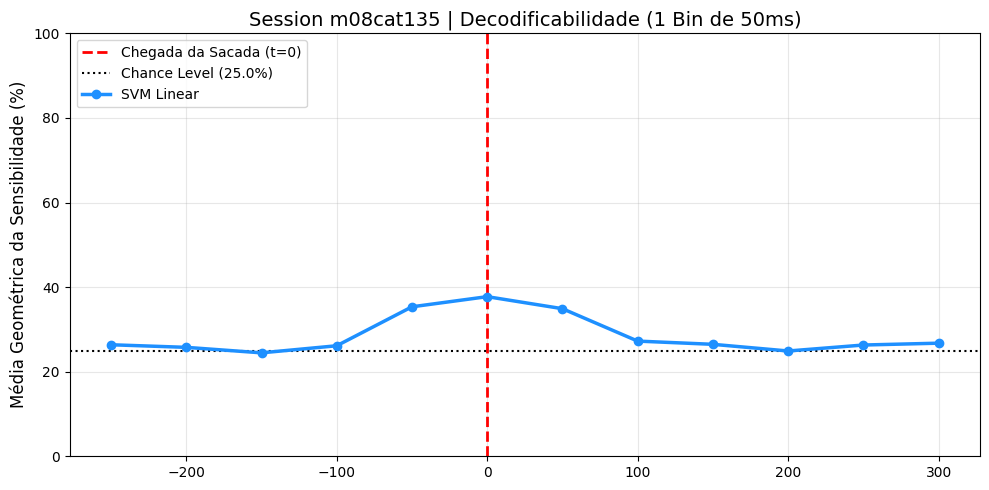

In [57]:
plot_decoding(res_category)